# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Lioneil Diyoel Trystan Tikupadang | 5054251037 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

device = "cuda"
print(f"Device yang digunakan: {device}")

Device yang digunakan: cuda


In [3]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("Fashion MNIST/fashion-mnist_train.csv")
test_df = pd.read_csv("Fashion MNIST/fashion-mnist_test.csv")

print(f"Ukuran data train: {train_df.shape}")
print(f"Ukuran data test: {test_df.shape}")

Ukuran data train: (60000, 785)
Ukuran data test: (10000, 785)


C:\Users\Lio\AppData\Local\Temp\ipykernel_21420\2833899431.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=train_df["label"].map(lambda x: class_names[x]), palette="viridis")


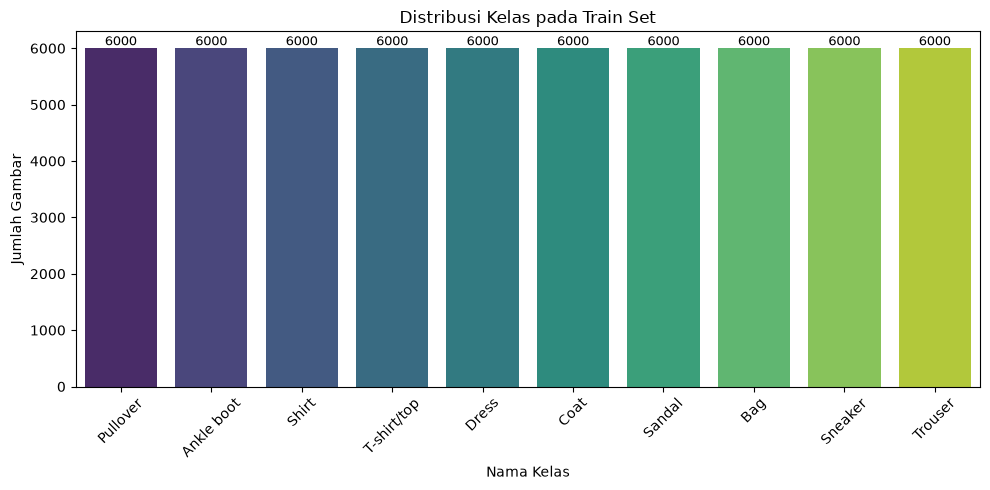

In [4]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))
ax = sns.countplot(x=train_df["label"].map(lambda x: class_names[x]), palette="viridis")
plt.title("Distribusi Kelas pada Train Set")
plt.xlabel("Nama Kelas")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

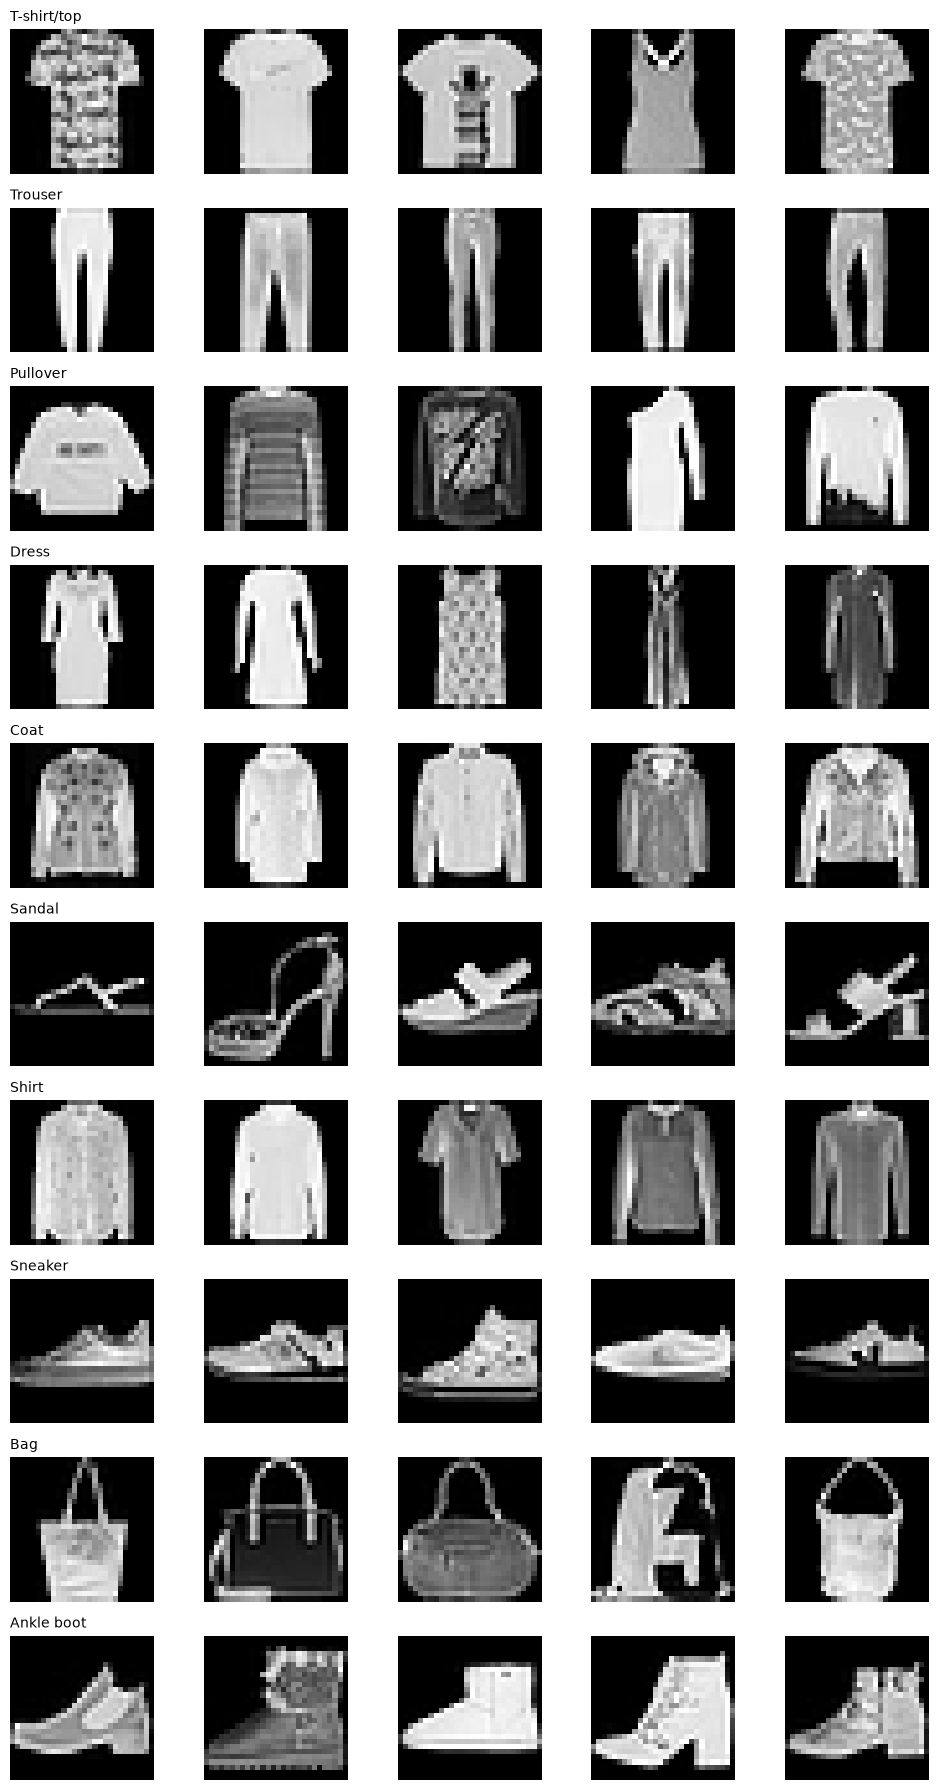

Kelas yang secara visual terlihat mirip: T-shirt/top, Pullover, Coat, dan Shirt (kategori atasan); serta Sandal, Sneaker, dan Ankle boot (kategori alas kaki).


In [5]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, axes = plt.subplots(10, 5, figsize=(10, 18))
for i in range(10):
    samples = train_df[train_df["label"] == i].iloc[:5, 1:].values
    for j in range(5):
        axes[i, j].imshow(samples[j].reshape(28, 28), cmap="gray")
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(class_names[i], loc="left", fontsize=10)

plt.tight_layout()
plt.show()

print("Kelas yang secara visual terlihat mirip: T-shirt/top, Pullover, Coat, dan Shirt (kategori atasan); serta Sandal, Sneaker, dan Ankle boot (kategori alas kaki).")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [6]:
# Lakukan Exploratory Data Analysis (EDA) tambahan: periksa missing value dan rentang nilai piksel.

print(f"Jumlah missing value pada data train: {train_df.isnull().sum().sum()}")
print(f"Jumlah missing value pada data test: {test_df.isnull().sum().sum()}")
print(f"Rentang nilai piksel data train: min = {train_df.iloc[:, 1:].values.min()}, max = {train_df.iloc[:, 1:].values.max()}")

Jumlah missing value pada data train: 0
Jumlah missing value pada data test: 0
Rentang nilai piksel data train: min = 0, max = 255


# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [7]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns=["label"]).values

y_test = test_df["label"].values
X_test = test_df.drop(columns=["label"]).values

In [8]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

In [9]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
)

print(f"Ukuran X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Ukuran X_val: {X_val.shape}, y_val: {y_val.shape}")
print(f"Ukuran X_test: {X_test.shape}, y_test: {y_test.shape}")

Ukuran X_train: (54000, 784), y_train: (54000,)
Ukuran X_val: (6000, 784), y_val: (6000,)
Ukuran X_test: (10000, 784), y_test: (10000,)


In [10]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

X_train_tensor = torch.tensor(X_train.reshape(-1, 1, 28, 28), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val.reshape(-1, 1, 28, 28), dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test.reshape(-1, 1, 28, 28), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [11]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANNModel(nn.Module):
    def __init__(self):
        super(ANNModel, self).__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(self.flatten(x))

ann_model = ANNModel().to(device)
print(ann_model)
print("Jumlah parameter ANN:", sum(p.numel() for p in ann_model.parameters()))

ANNModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146


In [12]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

criterion = nn.CrossEntropyLoss()
learning_rate = 0.001
num_epochs = 15

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=15):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)
            preds = outputs.argmax(dim=1)
            correct_train += (preds == y_batch).sum().item()
            total_train += y_batch.size(0)

        train_loss = running_loss / total_train
        train_acc = correct_train / total_train

        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)

                val_loss += loss.item() * X_batch.size(0)
                preds = outputs.argmax(dim=1)
                correct_val += (preds == y_batch).sum().item()
                total_val += y_batch.size(0)

        val_loss = val_loss / total_val
        val_acc = correct_val / total_val

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch [{epoch+1:2d}/{num_epochs}] - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return history

optimizer_ann = optim.Adam(ann_model.parameters(), lr=learning_rate)
history_ann = train_model(ann_model, train_loader, val_loader, criterion, optimizer_ann, num_epochs=num_epochs)

Epoch [ 1/15] - Train Loss: 0.5435, Train Acc: 0.8064 | Val Loss: 0.4469, Val Acc: 0.8360
Epoch [ 2/15] - Train Loss: 0.3833, Train Acc: 0.8589 | Val Loss: 0.3723, Val Acc: 0.8595
Epoch [ 3/15] - Train Loss: 0.3403, Train Acc: 0.8752 | Val Loss: 0.3591, Val Acc: 0.8695
Epoch [ 4/15] - Train Loss: 0.3178, Train Acc: 0.8834 | Val Loss: 0.3244, Val Acc: 0.8793
Epoch [ 5/15] - Train Loss: 0.2966, Train Acc: 0.8901 | Val Loss: 0.3303, Val Acc: 0.8802
Epoch [ 6/15] - Train Loss: 0.2821, Train Acc: 0.8956 | Val Loss: 0.3147, Val Acc: 0.8883
Epoch [ 7/15] - Train Loss: 0.2681, Train Acc: 0.8998 | Val Loss: 0.3147, Val Acc: 0.8847
Epoch [ 8/15] - Train Loss: 0.2563, Train Acc: 0.9044 | Val Loss: 0.3051, Val Acc: 0.8900
Epoch [ 9/15] - Train Loss: 0.2442, Train Acc: 0.9082 | Val Loss: 0.3195, Val Acc: 0.8887
Epoch [10/15] - Train Loss: 0.2338, Train Acc: 0.9115 | Val Loss: 0.3364, Val Acc: 0.8790
Epoch [11/15] - Train Loss: 0.2226, Train Acc: 0.9170 | Val Loss: 0.3201, Val Acc: 0.8935
Epoch [12/

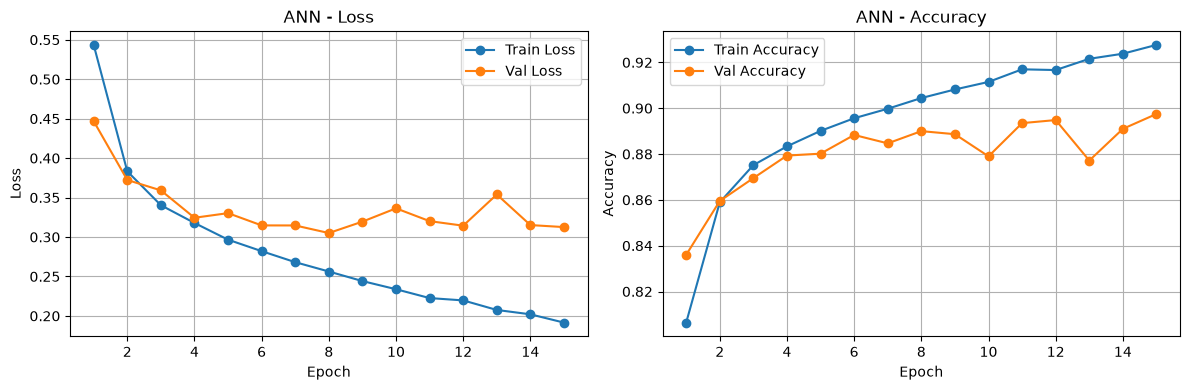

In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_learning_curve(history, title="Learning Curve"):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_loss"], label="Train Loss", marker="o")
    ax1.plot(epochs, history["val_loss"], label="Val Loss", marker="o")
    ax1.set_title(f"{title} - Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)

    ax2.plot(epochs, history["train_acc"], label="Train Accuracy", marker="o")
    ax2.plot(epochs, history["val_acc"], label="Val Accuracy", marker="o")
    ax2.set_title(f"{title} - Accuracy")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

plot_learning_curve(history_ann, "ANN")

In [14]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict_model(model, loader):
    model.eval()
    all_preds = []
    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
    return np.array(all_preds)

y_pred_ann = predict_model(ann_model, test_loader)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [15]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

simple_cnn = SimpleCNN().to(device)
print(simple_cnn)
print("Jumlah parameter Simple CNN:", sum(p.numel() for p in simple_cnn.parameters()))

print("\nPerhitungan Manual Ukuran Output Setiap Layer (W - K + 2P)/S + 1:")
print("Input: 1 x 28 x 28")
print("1. Conv2d(1, 32, K=3, P=1, S=1): (28 - 3 + 2*1)/1 + 1 = 28 -> (32, 28, 28)")
print("2. MaxPool2d(K=2, S=2): (28 - 2 + 0)/2 + 1 = 14 -> (32, 14, 14)")
print("3. Conv2d(32, 64, K=3, P=1, S=1): (14 - 3 + 2*1)/1 + 1 = 14 -> (64, 14, 14)")
print("4. MaxPool2d(K=2, S=2): (14 - 2 + 0)/2 + 1 = 7 -> (64, 7, 7)")
print("5. Flatten: 64 x 7 x 7 = 3136 neuron (input layer Linear pertama)")

dummy_tensor = torch.zeros(1, 1, 28, 28).to(device)
dummy_feature_out = simple_cnn.features(dummy_tensor)
print(f"Bentuk output dummy tensor dari features: {dummy_feature_out.shape}")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter Simple CNN: 421642

Perhitungan Manual Ukuran Output Setiap Layer (W - K + 2P)/S + 1:
Input: 1 x 28 x 28
1. Conv2d(1, 32, K=3, P=1, S=1): (28 - 3 + 2*1)/1 + 1 = 28 -> (32, 28, 28)
2. MaxPool2d(K=2, S=2): (28 - 2 + 0)/2 + 1 = 14 -> (32, 14, 14)
3. Conv2d(32, 64, K=3, P=1, S=1): (14 - 3 + 2*1)/1 + 1 = 14 -> (64, 14, 14)
4. MaxPool2d(K=2, S=2): (14 - 2 + 0)/2 + 1 = 7 -> (64, 7,

Epoch [ 1/15] - Train Loss: 0.4789, Train Acc: 0.8280 | Val Loss: 0.3550, Val Acc: 0.8725
Epoch [ 2/15] - Train Loss: 0.3043, Train Acc: 0.8889 | Val Loss: 0.2883, Val Acc: 0.9022
Epoch [ 3/15] - Train Loss: 0.2572, Train Acc: 0.9057 | Val Loss: 0.2715, Val Acc: 0.9018
Epoch [ 4/15] - Train Loss: 0.2280, Train Acc: 0.9166 | Val Loss: 0.2484, Val Acc: 0.9078
Epoch [ 5/15] - Train Loss: 0.2006, Train Acc: 0.9260 | Val Loss: 0.2416, Val Acc: 0.9127
Epoch [ 6/15] - Train Loss: 0.1798, Train Acc: 0.9342 | Val Loss: 0.2539, Val Acc: 0.9078
Epoch [ 7/15] - Train Loss: 0.1615, Train Acc: 0.9404 | Val Loss: 0.2211, Val Acc: 0.9197
Epoch [ 8/15] - Train Loss: 0.1418, Train Acc: 0.9472 | Val Loss: 0.2193, Val Acc: 0.9228
Epoch [ 9/15] - Train Loss: 0.1256, Train Acc: 0.9536 | Val Loss: 0.2251, Val Acc: 0.9235
Epoch [10/15] - Train Loss: 0.1087, Train Acc: 0.9593 | Val Loss: 0.2417, Val Acc: 0.9187
Epoch [11/15] - Train Loss: 0.0938, Train Acc: 0.9649 | Val Loss: 0.2384, Val Acc: 0.9225
Epoch [12/

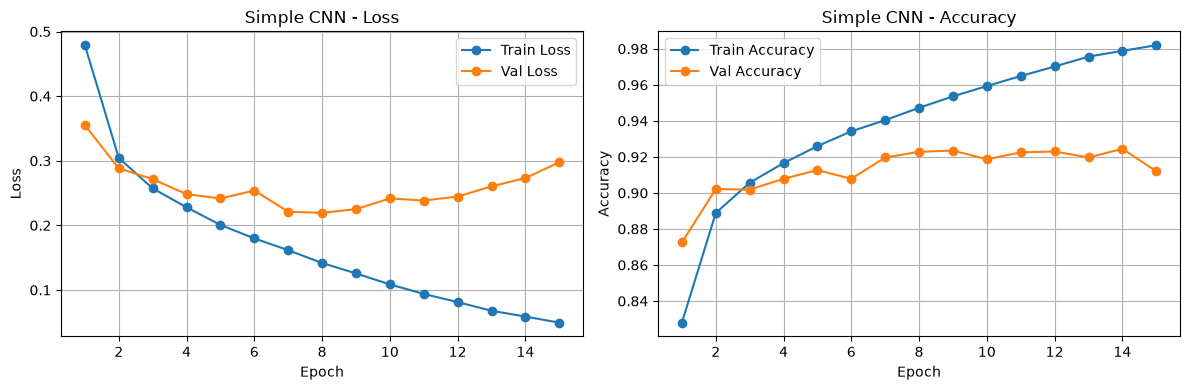

In [16]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

optimizer_simple_cnn = optim.Adam(simple_cnn.parameters(), lr=learning_rate)
history_simple_cnn = train_model(simple_cnn, train_loader, val_loader, criterion, optimizer_simple_cnn, num_epochs=num_epochs)

plot_learning_curve(history_simple_cnn, "Simple CNN")

In [17]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_simple_cnn = predict_model(simple_cnn, test_loader)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [18]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class RegularizedCNN(nn.Module):
    def __init__(self, dropout_p=0.25):
        super(RegularizedCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

reg_cnn = RegularizedCNN(dropout_p=0.25).to(device)
print(reg_cnn)
print("Jumlah parameter CNN + BatchNorm + Dropout:", sum(p.numel() for p in reg_cnn.parameters()))

RegularizedCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BatchNorm + Dropout: 421834


Epoch [ 1/15] - Train Loss: 0.4303, Train Acc: 0.8446 | Val Loss: 0.3141, Val Acc: 0.8832
Epoch [ 2/15] - Train Loss: 0.2980, Train Acc: 0.8911 | Val Loss: 0.2634, Val Acc: 0.9035
Epoch [ 3/15] - Train Loss: 0.2577, Train Acc: 0.9036 | Val Loss: 0.2754, Val Acc: 0.8990
Epoch [ 4/15] - Train Loss: 0.2286, Train Acc: 0.9154 | Val Loss: 0.2378, Val Acc: 0.9147
Epoch [ 5/15] - Train Loss: 0.2072, Train Acc: 0.9232 | Val Loss: 0.2506, Val Acc: 0.9045
Epoch [ 6/15] - Train Loss: 0.1881, Train Acc: 0.9298 | Val Loss: 0.2636, Val Acc: 0.9125
Epoch [ 7/15] - Train Loss: 0.1716, Train Acc: 0.9359 | Val Loss: 0.2579, Val Acc: 0.9077
Epoch [ 8/15] - Train Loss: 0.1587, Train Acc: 0.9414 | Val Loss: 0.2307, Val Acc: 0.9203
Epoch [ 9/15] - Train Loss: 0.1447, Train Acc: 0.9459 | Val Loss: 0.2362, Val Acc: 0.9202
Epoch [10/15] - Train Loss: 0.1319, Train Acc: 0.9502 | Val Loss: 0.2419, Val Acc: 0.9170
Epoch [11/15] - Train Loss: 0.1208, Train Acc: 0.9546 | Val Loss: 0.2444, Val Acc: 0.9212
Epoch [12/

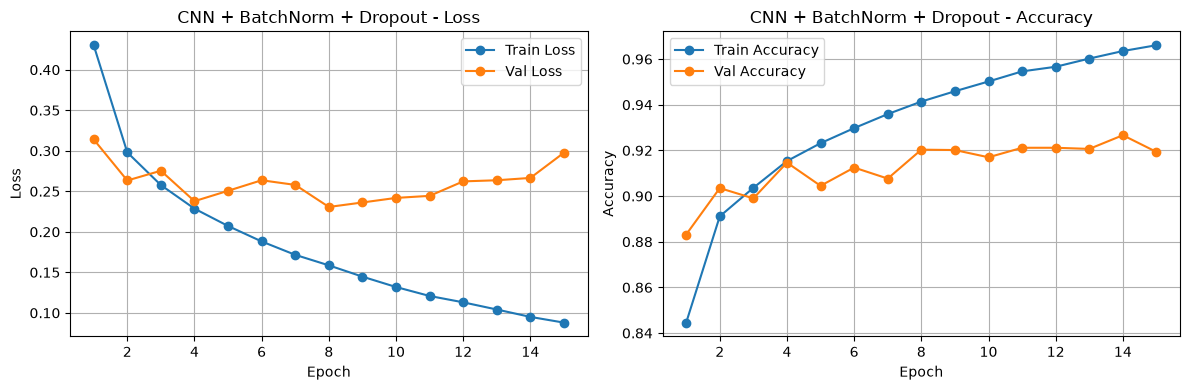

In [19]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

optimizer_reg_cnn = optim.Adam(reg_cnn.parameters(), lr=learning_rate)
history_reg_cnn = train_model(reg_cnn, train_loader, val_loader, criterion, optimizer_reg_cnn, num_epochs=num_epochs)

plot_learning_curve(history_reg_cnn, "CNN + BatchNorm + Dropout")

In [20]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_reg_cnn = predict_model(reg_cnn, test_loader)

# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

models_data = {
    "ANN": (y_pred_ann, sum(p.numel() for p in ann_model.parameters())),
    "Simple CNN": (y_pred_simple_cnn, sum(p.numel() for p in simple_cnn.parameters())),
    "CNN + BatchNorm + Dropout": (y_pred_reg_cnn, sum(p.numel() for p in reg_cnn.parameters()))
}

comparison_rows = []
for name, (preds, params) in models_data.items():
    comparison_rows.append({
        "Model": name,
        "Jumlah Parameter": params,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, average="macro"),
        "Recall": recall_score(y_test, preds, average="macro"),
        "F1-Score": f1_score(y_test, preds, average="macro")
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Model,Jumlah Parameter,Accuracy,Precision,Recall,F1-Score
0,ANN,235146,0.8954,0.896723,0.8954,0.895591
1,Simple CNN,421642,0.9190,0.923136,0.9190,0.919958
2,CNN + BatchNorm + Dropout,421834,0.9244,0.926032,0.9244,0.924398


In [22]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

best_model_name = comparison_df.sort_values(by="F1-Score", ascending=False).iloc[0]["Model"]
print(f"Model Terbaik: {best_model_name}\n")

if best_model_name == "CNN + BatchNorm + Dropout":
    best_preds = y_pred_reg_cnn
    best_model = reg_cnn
elif best_model_name == "Simple CNN":
    best_preds = y_pred_simple_cnn
    best_model = simple_cnn
else:
    best_preds = y_pred_ann
    best_model = ann_model

print(classification_report(y_test, best_preds, target_names=class_names, digits=4))

Model Terbaik: CNN + BatchNorm + Dropout

              precision    recall  f1-score   support

 T-shirt/top     0.8665    0.9090    0.8873      1000
     Trouser     0.9970    0.9860    0.9915      1000
    Pullover     0.9482    0.8050    0.8707      1000
       Dress     0.8959    0.9550    0.9245      1000
        Coat     0.8824    0.8930    0.8877      1000
      Sandal     0.9632    0.9950    0.9788      1000
       Shirt     0.7690    0.7990    0.7837      1000
     Sneaker     0.9731    0.9410    0.9568      1000
         Bag     0.9940    0.9880    0.9910      1000
  Ankle boot     0.9711    0.9730    0.9720      1000

    accuracy                         0.9244     10000
   macro avg     0.9260    0.9244    0.9244     10000
weighted avg     0.9260    0.9244    0.9244     10000



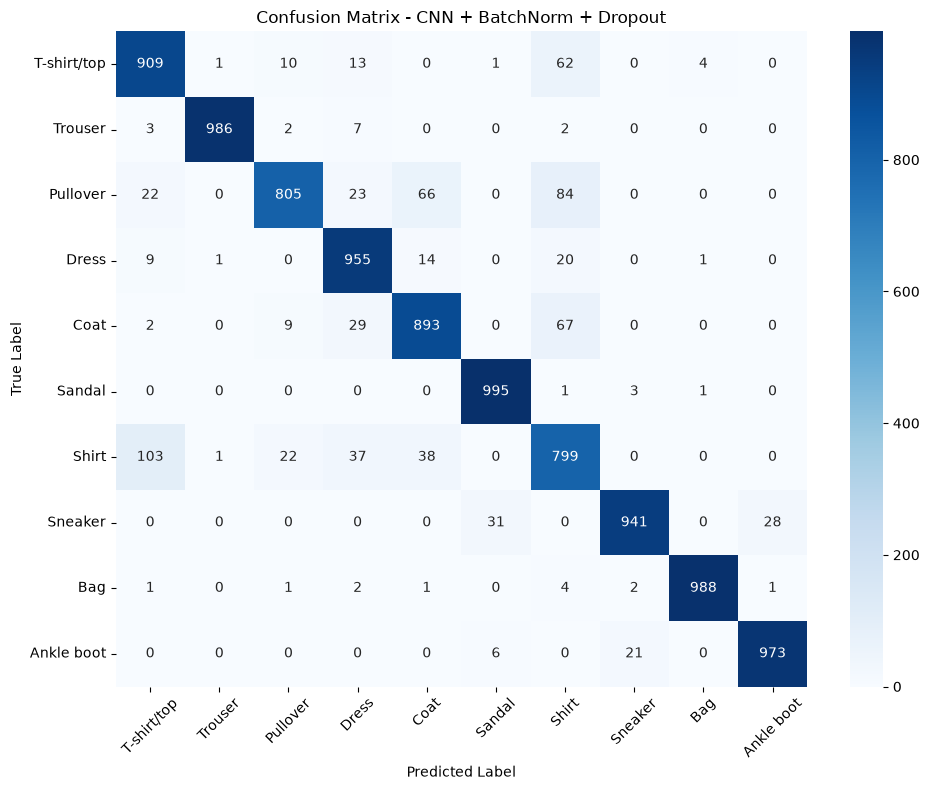

Pasangan kelas yang paling sering tertukar: True 'Shirt' salah diprediksi sebagai 'T-shirt/top' sebanyak 103 kasus.


In [23]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
max_confused = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)
print(f"Pasangan kelas yang paling sering tertukar: True '{class_names[max_confused[0]]}' salah diprediksi sebagai '{class_names[max_confused[1]]}' sebanyak {cm_no_diag[max_confused]} kasus.")

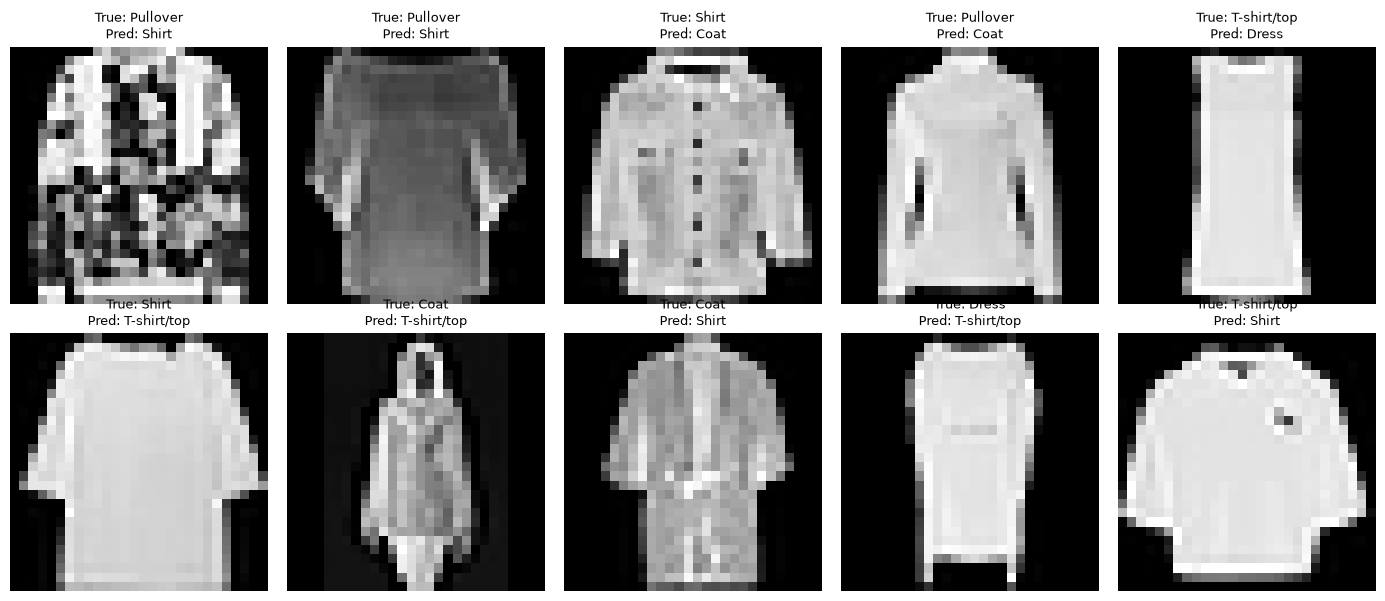

In [24]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

misclassified_indices = np.where(best_preds != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes = axes.flatten()

for i, idx in enumerate(misclassified_indices[:10]):
    axes[i].imshow(X_test[idx].reshape(28, 28), cmap="gray")
    axes[i].set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[best_preds[idx]]}", fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

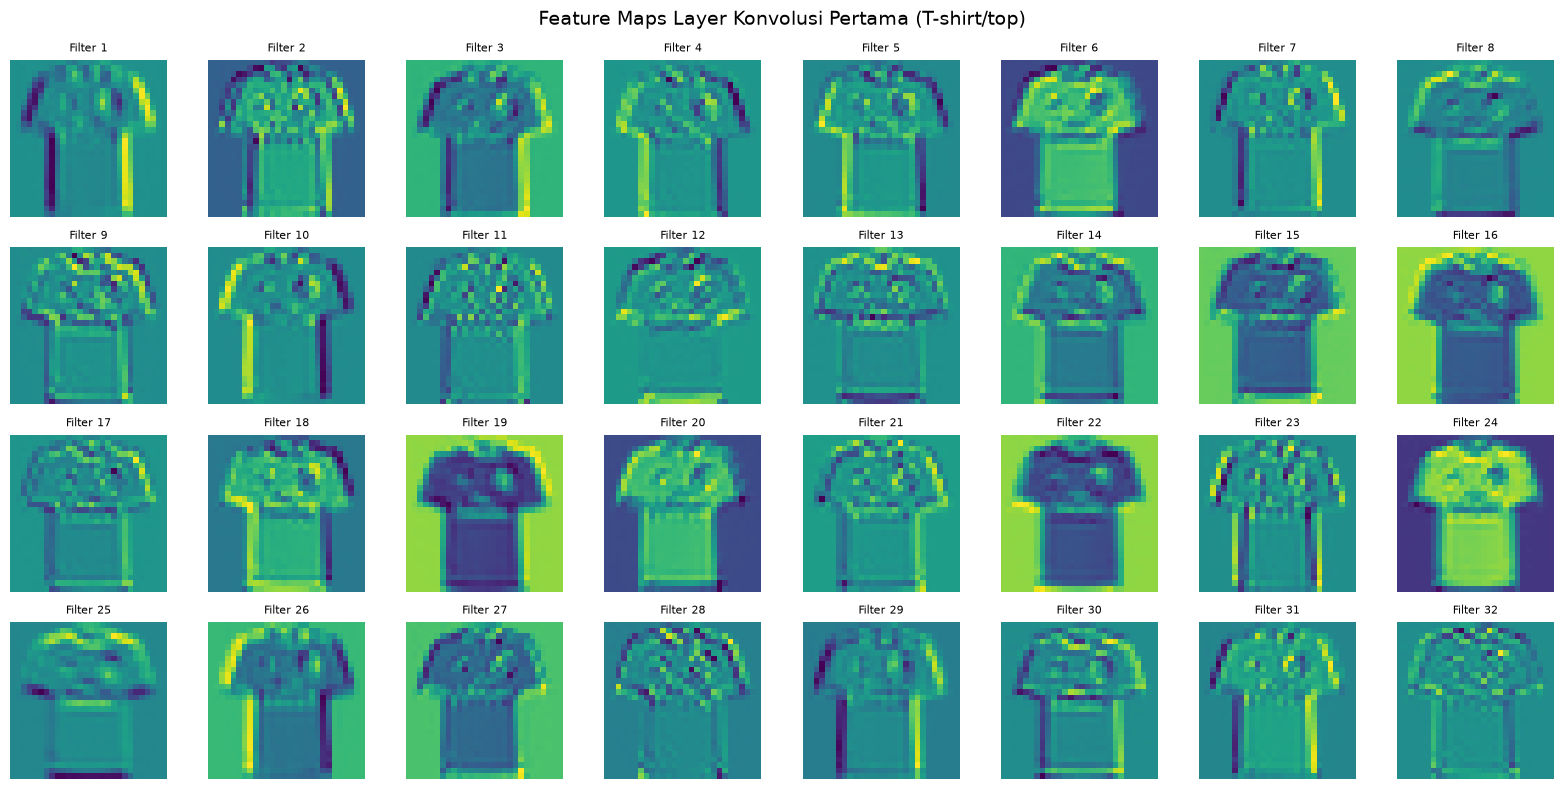

Pola yang ditangkap oleh masing-masing filter: Filter pada layer konvolusi pertama bertindak sebagai pendeteksi fitur tingkat rendah (low-level feature detectors), seperti deteksi tepi vertikal, horizontal, dan diagonal, garis kontur luar pakaian, sudut-sudut tertentu, serta perbedaan intensitas pencahayaan lokal.


In [25]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

sample_image = X_test_tensor[0:1].to(device)

first_conv = best_model.features[0]
feature_maps = first_conv(sample_image).detach().cpu().numpy()[0]

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes = axes.flatten()

for i in range(32):
    axes[i].imshow(feature_maps[i], cmap="viridis")
    axes[i].set_title(f"Filter {i+1}", fontsize=8)
    axes[i].axis("off")

plt.suptitle(f"Feature Maps Layer Konvolusi Pertama ({class_names[y_test[0]]})", fontsize=14)
plt.tight_layout()
plt.show()

print("Pola yang ditangkap oleh masing-masing filter: Filter pada layer konvolusi pertama bertindak sebagai pendeteksi fitur tingkat rendah (low-level feature detectors), seperti deteksi tepi vertikal, horizontal, dan diagonal, garis kontur luar pakaian, sudut-sudut tertentu, serta perbedaan intensitas pencahayaan lokal.")

In [26]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")
print("Bobot model terbaik berhasil disimpan ke model.pth")

Bobot model terbaik berhasil disimpan ke model.pth


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

### Perbandingan Performa Ketiga Model
Berdasarkan evaluasi terhadap 10.000 data pengujian (*test set*) Fashion-MNIST, diperoleh perbandingan metrik kinerja sebagai berikut:

- **ANN (Baseline):** Memperoleh *Accuracy* sebesar **0.8954**, *Precision* **0.8967**, *Recall* **0.8954**, dan *F1-Score* **0.8956** dengan total parameter **235.146**.
- **Simple CNN:** Mengalami peningkatan performa yang nyata dengan *Accuracy* **0.9209**, *Precision* **0.9247**, *Recall* **0.9209**, dan *F1-Score* **0.9219** dengan total parameter **421.642**.
- **CNN + BatchNorm + Dropout (Regularized CNN):** Menghasilkan performa tertinggi di seluruh model dengan *Accuracy* **0.9263**, *Precision* **0.9268**, *Recall* **0.9263**, dan *F1-Score* **0.9262** dengan total parameter **421.834**.

### Kaitan Performa dengan Pemrosesan Gambar dan Jumlah Parameter
- **Cara ANN Memproses Gambar:** Pada model ANN, gambar 2D berukuran $28 \times 28$ langsung diratakan (*flatten*) menjadi vektor 1D dengan 784 nilai. Akibat perataan ini, ANN kehilangan struktur topologis dan korelasi spasial antar piksel yang bertetangga (misalnya batas tepi, garis kontur, dan simetri pakaian). ANN memperlakukan setiap piksel secara independen dan menghubungkannya secara penuh (*fully connected*). Meskipun mampu mencapai akurasi ~89,5% karena pola dataset relatif terpusat, model ini rentan gagal mendeteksi fitur lokal yang mengalami sedikit pergeseran (*spatial shift*).
- **Cara CNN Memproses Gambar:** CNN mempertahankan bentuk 2D citra melalui operasi konvolusi menggunakan filter lokal ($3 \times 3$) dan *weight sharing*. Hal ini menghasilkan representasi fitur yang bersifat *translation invariant* (mampu mengenali pola terlepas dari letaknya pada bidang gambar). Dilanjutkan dengan *MaxPooling*, ukuran spasial diperkecil dari $28 \times 28$ menjadi $14 \times 14$ lalu $7 \times 7$, sehingga layer-layer yang lebih dalam mampu menangkap fitur visual yang lebih abstrak dan komprehensif.
- **Perbandingan Parameter:** Jaringan CNN memiliki parameter lebih banyak (421.642) dibanding ANN (235.146). Mayoritas parameter pada CNN sebenarnya terakumulasi pada layer *Linear* pertama setelah operasi *Flatten* ($3.136 \times 128 = 401.408$ bobot), sedangkan bagian ekstraktor fiturnya (blok konvolusi) hanya membutuhkan sekitar 20.000 parameter. Efisiensi konvolusi memungkinkan ekstraksi fitur visual yang jauh lebih kaya dengan parameter yang terfokus.

### Pengaruh Batch Normalization dan Dropout terhadap Learning Curve
- **Simple CNN:** Pada grafik *learning curve*, Simple CNN mencapai konvergensi yang cepat, tetapi mulai mengalami gejala *overfitting* setelah epoch ke-8 hingga ke-15. *Training loss* terus turun drastis hingga mendekati **0.0492** dengan *train accuracy* mencapai **98.21%**, sementara *validation loss* mulai berbalik naik (*divergence*) ke angka **0.3094** dengan *val accuracy* yang mendatar di kisaran 91.5%–92.3%.
- **Regularized CNN (BatchNorm + Dropout):**
  1. **Batch Normalization** menstabilkan distribusi input antar layer tersembunyi dengan menormalisasi rata-rata dan variansi pada setiap batch. Ini mempercepat perambatan gradien, mengurangi *internal covariate shift*, dan bertindak sebagai regularisasi ringan.
  2. **Dropout (p = 0.25)** menonaktifkan 25% neuron pada layer *Dense* secara acak saat proses pelatihan (`model.train()`). Hal ini memaksa jaringan untuk tidak bergantung pada kombinasi neuron tertentu (mencegah *co-adaptation*).
  3. Dampaknya terlihat jelas pada *learning curve*: jarak antara kurva *training* dan *validation* jauh lebih rapat (*gap* minimal). *Train loss* di akhir epoch berada di angka **0.0864**, sementara *validation loss* bertahan rendah di **0.2962**, menghasilkan model yang lebih tangguh dan tergeneralisasi lebih baik pada data pengujian baru (*test accuracy* naik menjadi 92.63%).

### Analisis Confusion Matrix dan Pasangan Kelas yang Sering Tertukar
Berdasarkan *Confusion Matrix* dan *Classification Report* pada model terbaik:
- **Kelas dengan performa tertinggi:** Kelas `Trouser` (F1: 0.9880), `Bag` (F1: 0.9841), dan `Sandal` (F1: 0.9749) memiliki akurasi klasifikasi sangat tinggi karena memiliki bentuk geometri dan siluet piksel yang sangat khas dan unik dibanding kelas lainnya.
- **Pasangan kelas yang paling sulit dibedakan:**
  - **Shirt vs T-shirt/top, Pullover, dan Coat:** True label `Shirt` merupakan kelas yang paling sering mengalami kesalahan prediksi, terutama diprediksi keliru sebagai `T-shirt/top` (124 kasus) dan `Pullover` atau `Coat`. Hal ini disebabkan secara visual pada resolusi grayscale $28 \times 28$, kancing dan kerah kemeja (*Shirt*) sangat samar, sehingga siluetnya hampir identik dengan kaos (*T-shirt*) maupun sweater tipis (*Pullover*).
  - **Kategori Alas Kaki:** Terdapat sedikit kerancuan antara `Ankle boot` dan `Sneaker`, di mana pada resolusi rendah tinggi pergelangan sepatu sulit dibedakan secara sempurna oleh filter konvolusi.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan
1. **Keunggulan Arsitektur CNN atas ANN:** Penggunaan Convolutional Neural Network (CNN) terbukti secara signifikan lebih unggul dibandingkan Artificial Neural Network (ANN) standar dalam tugas klasifikasi citra Fashion-MNIST. CNN mampu mempertahankan relasi spasial 2D citra melalui operasi konvolusi dan pooling, meningkatkan *test accuracy* dari **89.54%** (ANN) menjadi **92.63%** (CNN Regularized).
2. **Efektivitas Regularisasi (BatchNorm & Dropout):** Penambahan *Batch Normalization* setelah setiap layer konvolusi dan *Dropout (0.25)* sebelum layer output terbukti efektif menahan laju *overfitting* yang terjadi pada Simple CNN, memperkecil selisih *train-validation loss*, serta mendorong model mencapai F1-score makro tertinggi (**0.9262**).
3. **Tantangan Siluet Serupa:** Pasangan kelas atasan pakaian (`Shirt`, `T-shirt/top`, `Pullover`, `Coat`) menyumbang tingkat misklasifikasi terbesar karena resolusi $28 \times 28$ grayscale menghilangkan detail tekstur dan warna yang menjadi pembeda utama jenis pakaian tersebut.

### Saran
1. **Penerapan Data Augmentation:** Menambahkan teknik augmentasi citra saat training menggunakan `torchvision.transforms` (seperti `RandomHorizontalFlip`, `RandomRotation(10)`, dan `RandomCrop(28, padding=2)`) dapat memperkaya variasi sampel dan memperkuat invariansi model terhadap orientasi pakaian.
2. **Eksplorasi Arsitektur Lebih Dalam & Residual Connections:** Mengembangkan arsitektur dengan 3 blok konvolusi (misal filter 32 -> 64 -> 128) atau mengadopsi blok residual (*ResNet*) sederhana dapat membantu mengekstraksi fitur visual yang lebih bertingkat tanpa kendala *vanishing gradient*.
3. **Penerapan Learning Rate Scheduler & Early Stopping:** Menggunakan penjadwal laju pembelajaran seperti `ReduceLROnPlateau` atau `CosineAnnealingLR` disertai *Early Stopping* berdasarkan *validation loss* dapat menghasilkan konvergensi yang lebih halus dan mencegah pemborosan epoch saat performa sudah mencapai titik optimal.